# T2: Reasoning distillation with completion-only LoRA
Teacher: Qwen2.5-1.5B-Instruct. Student: Qwen2.5-0.5B-Instruct.
A fixed sample of 1,000 GSM8K training questions is sent to the teacher.
Teacher outputs with a wrong/missing final answer are excluded, never silently
replaced with GSM8K reference rationales. Synthetic questions are held out.


In [ ]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "code"))


In [1]:
from common import *
import re
from decimal import Decimal, InvalidOperation
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
import make_synthetic

seed_all(42)
TEACHER = "Qwen/Qwen2.5-1.5B-Instruct"
STUDENT = "Qwen/Qwen2.5-0.5B-Instruct"
SYSTEM = "Solve the arithmetic problem using at most 3 short lines of calculations (under 80 words). No headings or restatement. Finish with a separate line containing #### and ONLY the number. Example format: 3 * 4 = 12. 12 - 2 = 10.\n#### 10"
gsm = load_dataset("openai/gsm8k", "main")
train_ids = (
    np.random.default_rng(42).choice(len(gsm["train"]), 1000, replace=False).tolist()
)
test_ids = (
    np.random.default_rng(42).choice(len(gsm["test"]), 200, replace=False).tolist()
)
synthetic = json.loads((ROOT / "data" / "synthetic_questions.json").read_text())
save_json("t2_splits", {"train": train_ids, "test": test_ids})


def final_answer(text):
    matches = re.findall(r"####\s*([-+]?\d[\d,]*(?:\.\d+)?)", text)
    if not matches:
        return None
    try:
        return str(Decimal(matches[-1].replace(",", "")).normalize())
    except InvalidOperation:
        return None


def load_model(name):
    tokenizer = AutoTokenizer.from_pretrained(name, padding_side="left")
    tokenizer.pad_token = tokenizer.eos_token
    # The 0.5B SDPA prefill hit an Intel driver resource limit at batch 32.
    # Eager attention and batch 8 keep before/after student evaluation identical.
    attention = "eager" if name == STUDENT else "sdpa"
    model = AutoModelForCausalLM.from_pretrained(
        name, torch_dtype=torch.bfloat16, attn_implementation=attention
    ).to(DEVICE)
    return tokenizer, model


def prompt(tokenizer, question):
    return tokenizer.apply_chat_template(
        [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}],
        tokenize=False,
        add_generation_prompt=True,
    )


@torch.no_grad()
def generate(model, tokenizer, questions, max_new_tokens=192):
    model.eval()
    inputs = tokenizer(
        [prompt(tokenizer, q) for q in questions], return_tensors="pt", padding=True
    ).to(DEVICE)
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    return tokenizer.batch_decode(
        outputs[:, inputs.input_ids.shape[1] :], skip_special_tokens=True
    )


Created 100 questions in 20 families; integer arithmetic checks passed.


## Generate and verify teacher rationales
The exact-match check uses only the final numerical answer. It does not prove
every reasoning step is sound; the report explicitly discusses this limitation.


In [2]:
teacher_path = ROOT / "data" / "teacher_rationales.json"
records = json.loads(teacher_path.read_text()) if teacher_path.exists() else []
if len(records) < 1000:
    tokenizer, teacher = load_model(TEACHER)
    sync()
    start = time.perf_counter()
    for start_idx in range(len(records), 1000, 64):
        ids = train_ids[start_idx : start_idx + 64]
        rows = [gsm["train"][i] for i in ids]
        completions = generate(teacher, tokenizer, [r["question"] for r in rows])
        for index, row, completion in zip(ids, rows, completions):
            predicted = final_answer(completion)
            reference = final_answer(row["answer"])
            records.append(
                {
                    "gsm8k_index": index,
                    "question": row["question"],
                    "completion": completion,
                    "prediction": predicted,
                    "reference": reference,
                    "valid": predicted is not None and predicted == reference,
                }
            )
        teacher_path.write_text(json.dumps(records, indent=2), encoding="utf-8")
        print(
            "Teacher generated:",
            len(records),
            "accepted:",
            sum(r["valid"] for r in records),
            flush=True,
        )
    sync()
    save_json(
        "t2_teacher_generation",
        {"seconds": time.perf_counter() - start, "teacher": TEACHER, "prompt": SYSTEM},
    )
    del teacher
    torch.xpu.empty_cache()
# Repair answer formatting only when the last stated number independently
# matches the reference. Keep raw text for audit; never replace a wrong number.
for row in records:
    row.setdefault("raw_completion", row["completion"])
    if final_answer(row["completion"]) is None:
        numbers = re.findall(r"[-+]?\d[\d,]*(?:\.\d+)?", row["completion"])
        if (
            numbers
            and str(Decimal(numbers[-1].replace(",", "")).normalize())
            == row["reference"]
        ):
            row["completion"] += "\n#### " + format(Decimal(row["reference"]), "f")
            row["format_corrected"] = True
            row["prediction"] = row["reference"]
            row["valid"] = True
teacher_path.write_text(json.dumps(records, indent=2), encoding="utf-8")
accepted = [r for r in records if r["valid"]]
assert accepted
print("Accepted teacher rationales:", len(accepted), "Excluded:", 1000 - len(accepted))


Accepted teacher rationales: 475 Excluded: 525


## Evaluate the original student on the fixed held-out sets
Exact match requires the final-answer marker; missing markers count as wrong.
Greedy decoding and a 192-token cap are identical before and after training.


In [3]:
tokenizer, student = load_model(STUDENT)
evaluation = [
    {
        "set": "gsm8k",
        "id": i,
        "question": gsm["test"][i]["question"],
        "reference": final_answer(gsm["test"][i]["answer"]),
    }
    for i in test_ids
]
evaluation += [
    {
        "set": "synthetic",
        "id": r["id"],
        "question": r["question"],
        "reference": str(Decimal(r["answer"]).normalize()),
    }
    for r in synthetic
]


def evaluate_reasoning(model, label):
    path = ROOT / "results" / f"t2_{label}_predictions.json"
    rows = json.loads(path.read_text()) if path.exists() else []
    for start in range(len(rows), len(evaluation), 8):
        batch = evaluation[start : start + 8]
        completions = generate(model, tokenizer, [r["question"] for r in batch])
        for row, text in zip(batch, completions):
            answer = final_answer(text)
            rows.append(
                {
                    **row,
                    "completion": text,
                    "prediction": answer,
                    "correct": answer is not None and answer == row["reference"],
                }
            )
        path.write_text(json.dumps(rows, indent=2), encoding="utf-8")
        print(label, "evaluated:", len(rows), flush=True)
    return {
        s: 100 * np.mean([r["correct"] for r in rows if r["set"] == s])
        for s in ["gsm8k", "synthetic"]
    }


baseline = evaluate_reasoning(student, "original")
print("Original:", baseline)


original evaluated: 8
original evaluated: 16
original evaluated: 24
original evaluated: 32
original evaluated: 40
original evaluated: 48
original evaluated: 56
original evaluated: 64
original evaluated: 72
original evaluated: 80
original evaluated: 88
original evaluated: 96
original evaluated: 104
original evaluated: 112
original evaluated: 120
original evaluated: 128
original evaluated: 136
original evaluated: 144
original evaluated: 152
original evaluated: 160
original evaluated: 168
original evaluated: 176
original evaluated: 184
original evaluated: 192
original evaluated: 200
original evaluated: 208
original evaluated: 216
original evaluated: 224
original evaluated: 232
original evaluated: 240
original evaluated: 248
original evaluated: 256
original evaluated: 264
original evaluated: 272
original evaluated: 280
original evaluated: 288
original evaluated: 296
original evaluated: 300
Original: {'gsm8k': np.float64(0.0), 'synthetic': np.float64(0.0)}


## Tokenize with prompt masking and add LoRA
Only teacher-completion tokens contribute to $L=-\sum_t\log p_\theta(y_t\mid x,y_{<t})$.
LoRA learns $\Delta W=(\alpha/r)BA$ with $r=8$, $\alpha=16$ on query/value projections.


In [4]:
tokenizer.padding_side = "right"
config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
    task_type="CAUSAL_LM",
)
student = get_peft_model(student, config)
trainable = sum(p.numel() for p in student.parameters() if p.requires_grad)
total = sum(p.numel() for p in student.parameters())
examples = []
truncated = 0
for row in accepted:
    prefix = tokenizer(prompt(tokenizer, row["question"]), add_special_tokens=False)[
        "input_ids"
    ]
    completion = tokenizer(
        row["completion"] + tokenizer.eos_token, add_special_tokens=False
    )["input_ids"]
    # Keep whole reasoning traces: discard sequences over the recorded length budget.
    if len(prefix) + len(completion) > 512:
        truncated += 1
        continue
    examples.append(
        {"input_ids": prefix + completion, "labels": [-100] * len(prefix) + completion}
    )


def collate(rows):
    length = max(len(r["input_ids"]) for r in rows)
    return {
        "input_ids": torch.tensor(
            [
                r["input_ids"]
                + [tokenizer.pad_token_id] * (length - len(r["input_ids"]))
                for r in rows
            ],
            device=DEVICE,
        ),
        "attention_mask": torch.tensor(
            [
                [1] * len(r["input_ids"]) + [0] * (length - len(r["input_ids"]))
                for r in rows
            ],
            device=DEVICE,
        ),
        "labels": torch.tensor(
            [r["labels"] + [-100] * (length - len(r["labels"])) for r in rows],
            device=DEVICE,
        ),
    }


batches = DataLoader(
    examples,
    batch_size=4,
    shuffle=True,
    collate_fn=collate,
    generator=torch.Generator().manual_seed(42),
)
optimizer = torch.optim.AdamW(
    [p for p in student.parameters() if p.requires_grad], lr=2e-4
)
print(
    "Training examples:",
    len(examples),
    "Trainable:",
    trainable,
    "Percent:",
    100 * trainable / total,
)


Training examples: 475 Trainable: 540672 Percent: 0.1093208725482711


## One epoch of completion-only supervised fine-tuning
Microbatch 4, gradient accumulation 4 (effective batch up to 16), AdamW.


In [5]:
student.train()
student.config.use_cache = False
losses = []
updates = 0
optimizer.zero_grad(set_to_none=True)
sync()
start = time.perf_counter()
for step, batch in enumerate(batches, 1):
    loss = student(**batch).loss
    losses.append(float(loss.detach()))
    group_size = min(4, len(batches) - ((step - 1) // 4) * 4)
    (loss / group_size).backward()
    if step % 4 == 0 or step == len(batches):
        torch.nn.utils.clip_grad_norm_(
            [p for p in student.parameters() if p.requires_grad], 1.0
        )
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        updates += 1
    if step % 20 == 0:
        print("Microbatch:", step, "Loss:", losses[-1], flush=True)
sync()
training_seconds = time.perf_counter() - start
student.save_pretrained(ROOT / "checkpoints" / "t2_lora")
tokenizer.save_pretrained(ROOT / "checkpoints" / "t2_lora")
student.config.use_cache = True


Microbatch: 20 Loss: 0.36668363213539124
Microbatch: 40 Loss: 0.4847668707370758
Microbatch: 60 Loss: 0.46288731694221497
Microbatch: 80 Loss: 0.42625680565834045
Microbatch: 100 Loss: 0.44324812293052673


## Evaluate the fine-tuned model and save comparable results


In [6]:
tokenizer.padding_side = "left"
finetuned = evaluate_reasoning(student, "finetuned")
result = {
    "teacher": TEACHER,
    "student": STUDENT,
    "sampled": 1000,
    "accepted": len(accepted),
    "format_corrected": sum(r.get("format_corrected", False) for r in records),
    "training_examples": len(examples),
    "overlength_excluded": truncated,
    "trainable_parameters": trainable,
    "total_parameters": total,
    "trainable_percent": 100 * trainable / total,
    "training_seconds": training_seconds,
    "optimizer_updates": updates,
    "microbatches": len(batches),
    "losses": losses,
    "original": baseline,
    "finetuned": finetuned,
    "seed": 42,
    "max_new_tokens": 192,
}
save_json("task2", result)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, len(losses) + 1), losses, alpha=0.6)
ax.set(xlabel="Training microbatch", ylabel="Completion cross-entropy")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "t2_loss.png", dpi=150)
plt.close(fig)
print(result)


finetuned evaluated: 8
finetuned evaluated: 16
finetuned evaluated: 24
finetuned evaluated: 32
finetuned evaluated: 40
finetuned evaluated: 48
finetuned evaluated: 56
finetuned evaluated: 64
finetuned evaluated: 72
finetuned evaluated: 80
finetuned evaluated: 88
finetuned evaluated: 96
finetuned evaluated: 104
finetuned evaluated: 112
finetuned evaluated: 120
finetuned evaluated: 128
finetuned evaluated: 136
finetuned evaluated: 144
finetuned evaluated: 152
finetuned evaluated: 160
finetuned evaluated: 168
finetuned evaluated: 176
finetuned evaluated: 184
finetuned evaluated: 192
finetuned evaluated: 200
finetuned evaluated: 208
finetuned evaluated: 216
finetuned evaluated: 224
finetuned evaluated: 232
finetuned evaluated: 240
finetuned evaluated: 248
finetuned evaluated: 256
finetuned evaluated: 264
finetuned evaluated: 272
finetuned evaluated: 280
finetuned evaluated: 288
finetuned evaluated: 296
finetuned evaluated: 300
{'teacher': 'Qwen/Qwen2.5-1.5B-Instruct', 'student': 'Qwen/Qwen

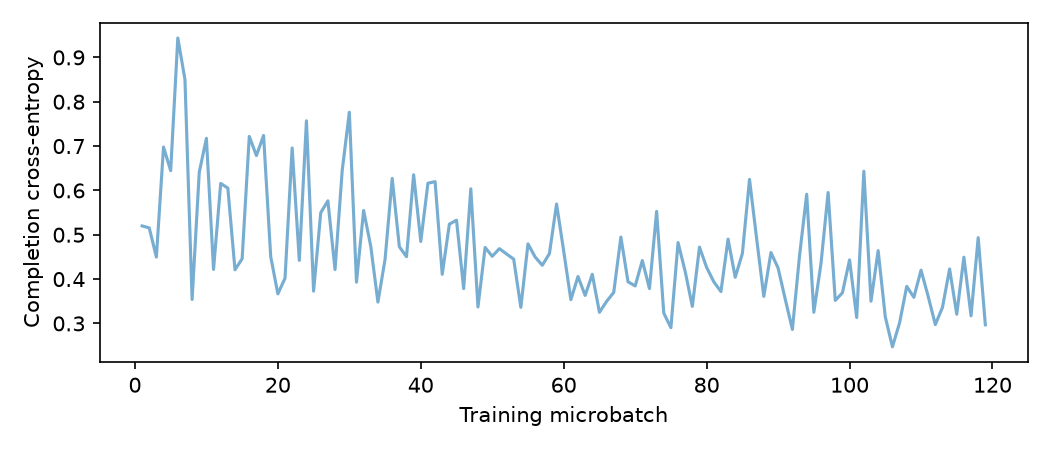

In [ ]:
from IPython.display import Image, display

display(Image(filename=str(project_root / "figures" / "t2_loss.png")))


# Analysis

## T2.1: Generate Held-Out Questions

**Q1.** Provide the generated dataset and teacher prompt. Describe how you checked the answers. Include examples of any errors encountered. How do your generated problems compare with GSM8K?

**Answer:**

The complete held-out set is `data/synthetic_questions.json`; the generation prompt is `results/synthetic_prompt.txt`. The set uses 20 multi-step arithmetic problem families, each instantiated with five deterministic parameter settings (100 unique questions). Generation uses programmatic parameter variants rather than 100 independent API completions. The explicit teacher prompt was:

> Generate 100 original GSM8K-style word problems with concise worked solutions ending in #### <value>. Use diverse multi-step arithmetic situations, unambiguous quantities, and exactly checkable integer answers. Keep these questions separate from GSM8K training. Include a programmatic arithmetic check for every answer.

All answers were recomputed with exact integer arithmetic from the stated quantities, and the final marker, uniqueness and count were checked. The chosen quantities make divisions exact; no synthetic arithmetic error was found. For example, the first problem makes 20 x 12 = 240 rolls, sells 2, and divides the remaining 238 between two shops: 119 rolls per shop. The full checking record is in `results/synthetic_checks.json`.

The set resembles GSM8K in short everyday stories and multi-step arithmetic, but has only 20 underlying structures, cleaner wording, exclusively integer final values and less linguistic diversity. Repeated structures make its accuracy a limited measure of general reasoning. No synthetic question or solution enters LoRA training.


## T2.2: Fine-Tune on Teacher Rationales

**Q1.** Report the number of training examples, trainable parameter count and percentage, training loss curve, and total training time. Briefly explain how the student learns from teacher-generated reasoning traces.

**Answer:**

| Training examples | Trainable parameters | Trainable (%) | Training loop (s) |
| --- | --- | --- | --- |
| 475 | 540672 | 0.11 | 103.19 |
A fixed seed-42 sample of 1,000 GSM8K training questions was answered by `Qwen/Qwen2.5-1.5B-Instruct`. 475 outputs matched the reference final number; 525 wrong or missing-answer outputs were excluded. An additional 0 accepted examples exceeded the 512-token budget and were excluded rather than truncating the rationale. The raw completions and accept/reject flags are in `data/teacher_rationales.json`. Matching the final answer does not establish that every intermediate reasoning step is correct.

For 430 accepted examples, a missing final-answer marker was corrected only because the last stated numerical value matched the GSM8K reference. Raw text is retained. Incorrect final numbers were never changed to reference values. The student is `Qwen/Qwen2.5-0.5B-Instruct`. LoRA uses rank 8, alpha 16 (scale 2), dropout 0.05, and `q_proj`/`v_proj` targets. AdamW uses learning rate 0.0002; microbatch size 4 with accumulation over 4 microbatches gives effective batch size up to 16. One epoch used 119 microbatches and 30 optimizer updates. The BF16 backbone is frozen; only LoRA parameters are trained. Prompt and padding tokens have label -100 and do not contribute to the objective. Teacher generation used SDPA attention in batches of 64. An Intel GPU resource failure during the initial student evaluation was resolved by switching both student evaluations to eager attention and batch size 8; no failed-run predictions were reused.

$$\Delta W=\frac{\alpha}{r}BA,\qquad L_{SFT}=-\sum_t\log p_\theta(y_t\mid x,y_{<t}).$$

The student learns to predict the teacher's calculation tokens and final answer, conditioned on the question and preceding completion tokens. This transfers a reasoning-output pattern using next-token supervision, without requiring teacher logits. The concise teacher prompt and all settings are in the notebook. A pilot prompt generated long responses that exceeded the token cap and responses such as `#### The total ... is 8 pounds`, which fail strict numerical extraction; those pilot records are retained separately and were not used for training.

![Completion-only training cross-entropy for each microbatch.](../figures/t2_loss.png)

Completion-only training cross-entropy for each microbatch.


## T2.3: Evaluate Reasoning

**Q1.** Compare the accuracy of the original and fine-tuned students on the real and synthetic questions. Show examples of correct and incorrect solutions. Did the model ever reach the correct answer through incorrect reasoning? How well did distillation transfer to the synthetic set?

**Answer:**

| Model | GSM8K accuracy (%) | Synthetic accuracy (%) |
| --- | --- | --- |
| Original student | 0.00 | 0.00 |
| Fine-tuned student | 19.50 | 21.00 |
Both students used the same 200 GSM8K test questions and all 100 synthetic questions, greedy decoding and a 192-token generation cap. Test questions were never used for model selection or training. Exact match extracts the last `####` numerical value, removes commas and compares normalized decimal values; missing markers count as incorrect. The fine-tuned model changed real-question accuracy by +19.50 points and synthetic accuracy by +21.00 points. The synthetic result applies to the limited family-based set described above, not unrestricted unseen arithmetic.

The review covers the same 20 questions for each model (10 GSM8K and 10 synthetic), giving 40 inspected solutions. The complete questions, raw outputs, references and individual reasoning assessments are in `results/t2_manual_review.json`. This is a targeted qualitative sample, not an estimate of the error rate across the whole dataset.

Formatting is a major confound: the original student produced a parseable required marker on 0/200 real and 1/100 synthetic questions, versus 148/200 and 96/100 after fine-tuning. Thus the strict exact-match gain cannot be interpreted solely as improved arithmetic. Some answers without the marker were mathematically correct; no reference-based formatting repair was applied to student evaluation outputs.

Examples from the inspected outputs:

| Set / ID | Model | Observed solution | Assessment |
|---|---|---|---|
| GSM8K / 645 | Original | 8 kg/portion x 3 bags = 24 kg | Omits 2 kg per portion; wrong reasoning and no marker. |
| GSM8K / 645 | Fine-tuned | 8 x 2 = 16; 16 x 3 = 48; `#### 48` | Correct reasoning and final answer. |
| GSM8K / 113 | Both | 2 x 15 - 5 = 25 | Both get the arithmetic right; only the fine-tuned output has `#### 25`. |
| GSM8K / 757 | Fine-tuned | 11 + 22 + 18 + 9 + 15 = 75; `#### 75` | Correct count relationships and sum; original used wrong large/extra-large counts. |
| GSM8K / 582 | Fine-tuned | 76000 x 0.3 = 22800; 76000 + 22800 = 98800 | Adds the discount amount instead of the discounted house value; reference is 129200. |
| Synthetic / 7 | Original / fine-tuned | Original evaluates 12 x 20 + 2 x 12 - 20 as 240; fine-tuned computes 264 - 20 = 244 | A genuine arithmetic correction, with a valid `#### 244` after fine-tuning. |
| Synthetic / 0 | Fine-tuned | 240 - 2 = 238; 238 / 2 = 119 | Correct arithmetic, still rejected because it uses a boxed answer instead of the required marker. |
| Synthetic / 1 | Original / fine-tuned | Original correctly gets 111; fine-tuned gives `#### 220` | A regression in reasoning despite improved formatting. |

No correct numerical answer reached through demonstrably incorrect reasoning was found in these 40 inspected outputs. This does not rule out such cases elsewhere. The fine-tuned model also truncates a correctly started ratio solution (GSM8K 116) before reaching its final answer, showing that the 192-token cap can reduce measured accuracy. Transfer to synthetic questions is mixed: some multiplication/subtraction errors are corrected, but unit errors, omitted quantities and regressions remain. The lower-diversity synthetic set and answer-format sensitivity limit any claim of broad reasoning generalization.
